# PRCP-1025-FlightPricePrediction

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
import math
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
df = pd.read_csv("Flight_Fare.csv")
df.shape

(10683, 11)

In [3]:
df

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


In [4]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [6]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [7]:
df.describe(include="O")

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


In [8]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(220)

In [10]:
duplicates = df[df.duplicated()]
duplicates.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
683,Jet Airways,1/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,14:35,04:25 02 Jun,13h 50m,2 stops,No info,13376
1061,Air India,21/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,22:00,19:15 22 May,21h 15m,2 stops,No info,10231
1348,Air India,18/05/2019,Delhi,Cochin,DEL → HYD → BOM → COK,17:15,19:15 19 May,26h,2 stops,No info,12392
1418,Jet Airways,6/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,05:30,04:25 07 Jun,22h 55m,2 stops,In-flight meal not included,10368
1674,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,18:25,21:20,2h 55m,non-stop,No info,7303


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 220


In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


In [14]:
df["Route"].nunique()

128

In [15]:
df["Additional_Info"].value_counts()

Additional_Info
No info                         8183
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [16]:
# Drop Route column
df.drop("Route", axis=1, inplace=True)

In [17]:
df

,Airline,Date_of_Journey,Source,Destination,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,11:30,14:10,2h 40m,non-stop,No info,12648


# EDA:

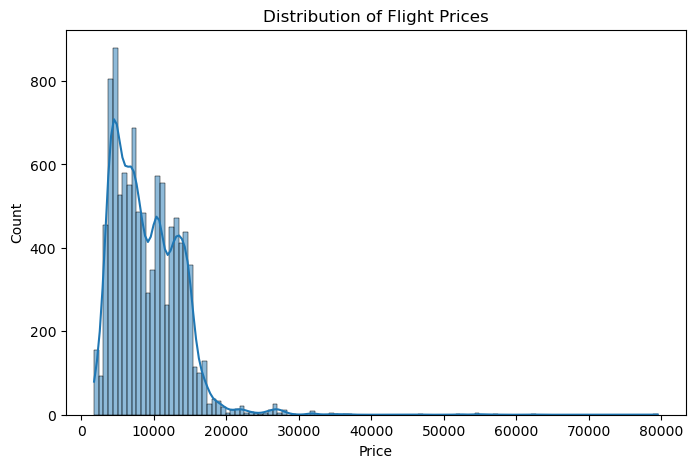

In [18]:
plt.figure(figsize=(8,5))
sns.histplot(df["Price"], kde=True)
plt.title("Distribution of Flight Prices")
plt.show()

Observation: Distribution of Flight Prices
The distribution of flight prices is positively (right) skewed.
Most ticket prices are concentrated between ₹3,000 and ₹15,000.
A small number of flights have much higher prices, creating a long tail on the right.
The data is not normally distributed.
The histogram shows that the majority of observations are clustered in the lower price range, while fewer observations exist at higher prices.
There are some high-priced flights (potential outliers).
Flight prices extend up to approximately ₹80,000.
These are likely premium or business-class flights rather than data errors.
Multiple peaks are visible.
This suggests different pricing groups, which may be due to different airlines, routes, travel durations, or booking conditions.

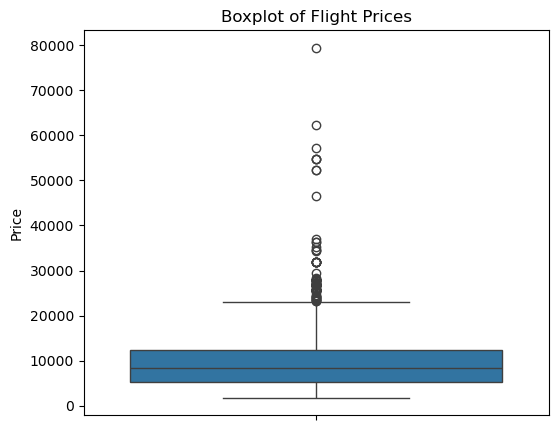

In [19]:
plt.figure(figsize=(6,5))
sns.boxplot(y=df["Price"])
plt.title("Boxplot of Flight Prices")
plt.show()

Observation:  
The distribution of flight prices is positively skewed, with most ticket prices ranging between ₹3,000 and ₹15,000. A small number of flights have significantly higher prices, resulting in a long right tail. These high-price values are likely genuine observations rather than errors, as airline ticket prices naturally vary based on factors such as airline, travel class, route, duration, and number of stops. Therefore, no outlier treatment is performed at this stage.

Although the boxplot identified several high-priced observations as outliers based on the IQR method, these values likely represent genuine premium flight fares rather than data errors. Therefore, no outlier treatment was applied to preserve the real-world distribution of ticket prices.

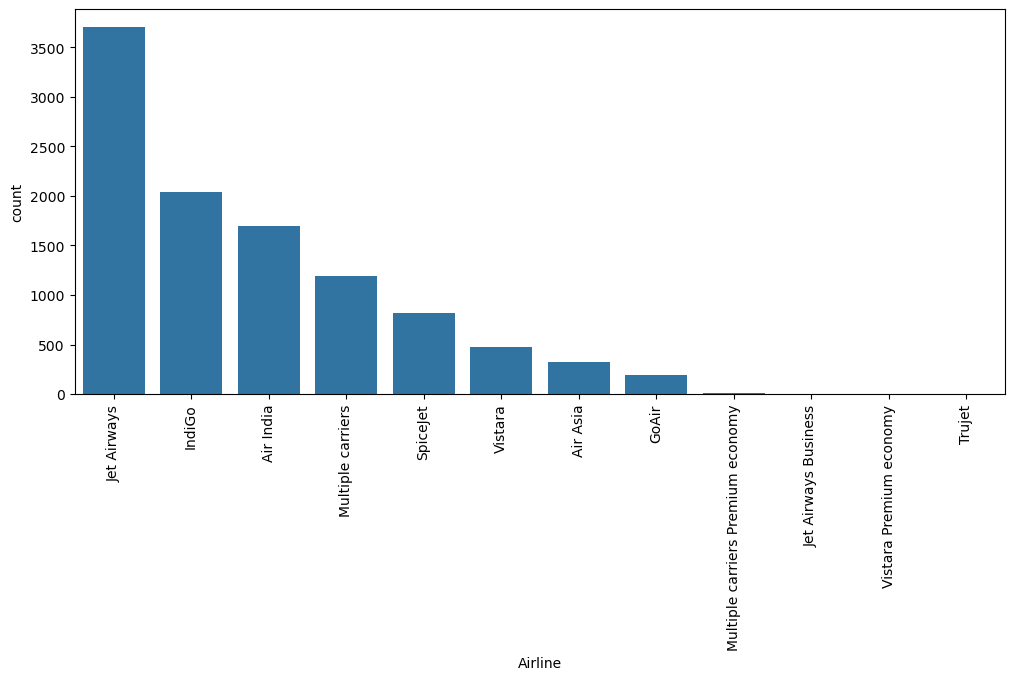

In [20]:
plt.figure(figsize=(12,5))
sns.countplot(data=df, x="Airline", order=df["Airline"].value_counts().index)
plt.xticks(rotation=90)
plt.show()

Observation:  

Jet Airways having highest price >3500,  
IndiGo airline having 2nd highest Price (2000),  
AirIndia Airline having 3rd highest price (1500-2000)


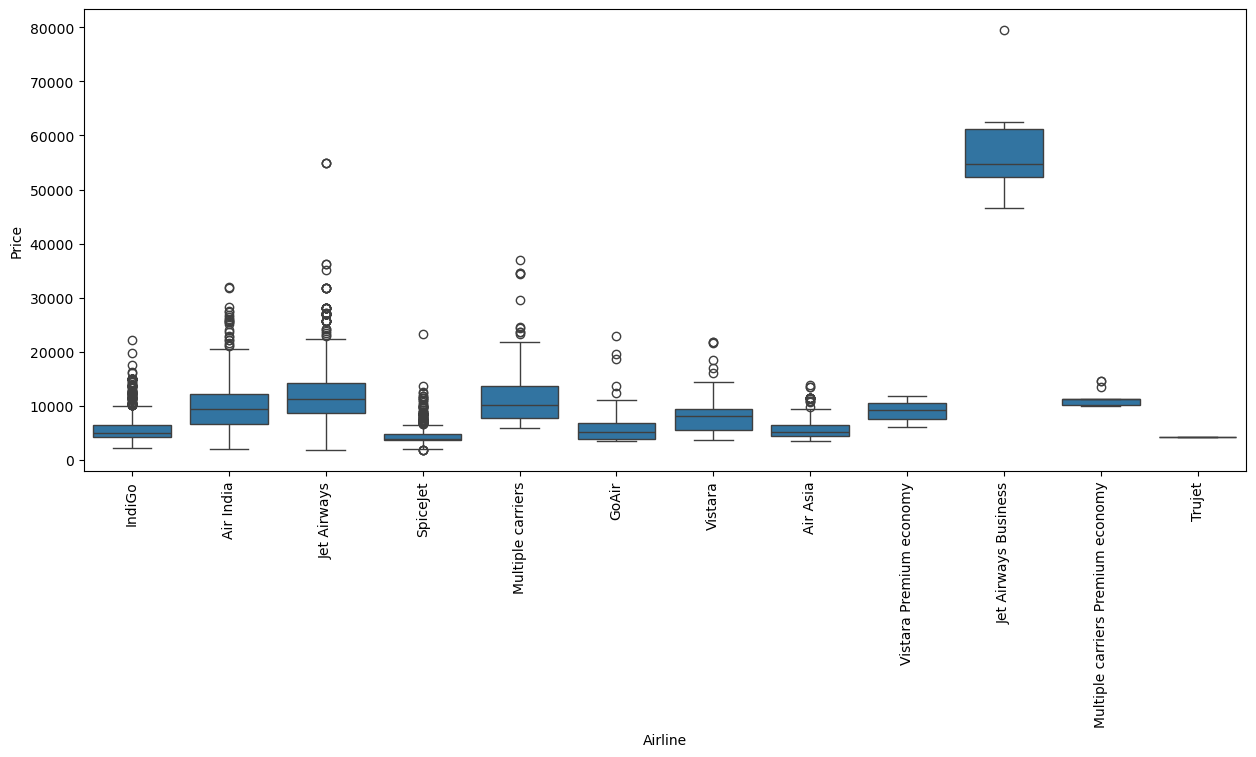

In [21]:
plt.figure(figsize=(15,6))
sns.boxplot(data=df, x="Airline", y="Price")
plt.xticks(rotation=90)
plt.show()

Observations:  
Jet Airways Business has the highest ticket prices.  
  -Median price is around ₹54,000–₹56,000.  
  -One flight is close to ₹80,000.  
  -This is expected because it represents business-class travel, not an error.  
Jet Airways has a wide price range.  
  -Median price is around ₹10,000–₹12,000.  
  -Several expensive tickets appear above ₹30,000, indicating premium fares.    
Multiple carriers and Air India also have higher price variability than airlines like IndiGo or SpiceJet.  
SpiceJet, GoAir, Air Asia, and Trujet generally have lower and more consistent ticket prices.  
Almost every airline has some high-priced observations. These are not isolated mistakes; they reflect real pricing differences.  

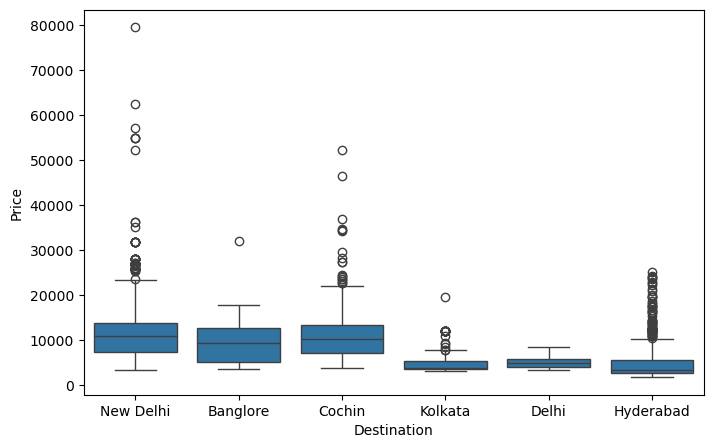

In [22]:
# Destination VS Price
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Destination", y="Price")
plt.show()

Observations: 

-Cochin and New Delhi have the highest median flight prices.  
-Flights to Kolkata, Delhi, and Hyderabad generally have lower median prices.  
-New Delhi shows the greatest price variability, with fares reaching nearly ₹80,000.  
-Several destinations contain high-priced outliers, indicating premium flights or higher demand.  
-Ticket prices vary considerably across destinations, suggesting that Destination is an important predictor of flight price.  

The destination of the flight significantly influences ticket prices. Flights to Cochin and New Delhi generally have higher fares compared to other destinations. The presence of several high-priced observations indicates that destination plays a major role in determining flight costs.

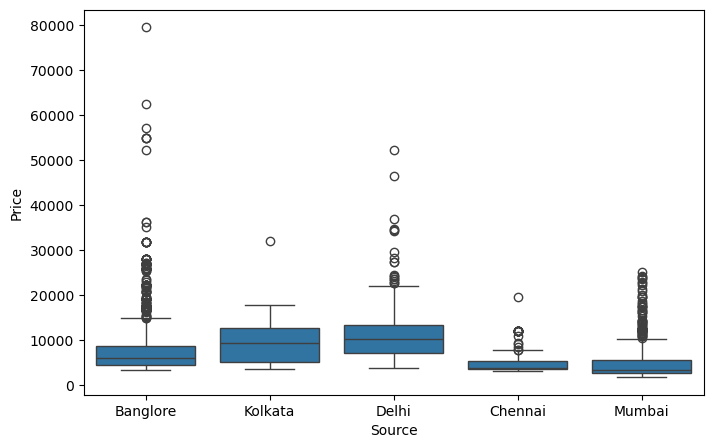

In [23]:
# Source VS Price
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Source", y="Price")
plt.show()

Observations:  
Flights originating from Delhi generally have higher median prices than most other sources.  
Flights from Bangalore show the largest variability and include the highest-priced tickets (up to approximately ₹80,000).  
Mumbai and Chennai have comparatively lower ticket prices.  
Price distributions differ across source cities, indicating that Source is an influential feature.  

Flight prices vary across departure cities. Bangalore and Delhi exhibit higher ticket prices and greater price variation, whereas Chennai and Mumbai generally have lower-priced flights. This indicates that the departure location has a significant impact on airfare.

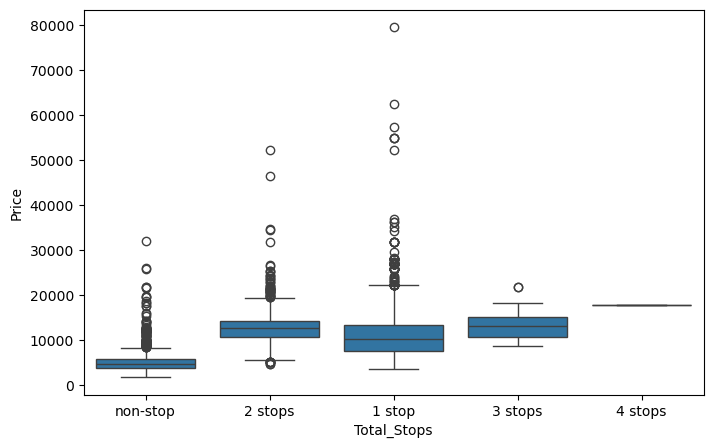

In [24]:
# Total_Stops VS Price
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Total_Stops", y="Price")
plt.show()

Observations  
Non-stop flights (0 stops) have the lowest median ticket prices.  
The median price generally increases as the number of stops increases.  
Flights with 3 or 4 stops are among the most expensive.  
One-stop and two-stop flights show greater variability, indicating that other factors such as airline, route, and duration also influence pricing.  
This suggests a positive relationship between the number of stops and flight price.  


The number of stops has a clear influence on flight prices. Flights with more stops generally have higher median ticket prices than non-stop flights. Therefore, Total Stops is expected to be an important predictor in the regression model.

In [25]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [26]:
df = df.dropna(subset=["Total_Stops"]).reset_index(drop=True)

In [27]:
print(df["Total_Stops"].isnull().sum())

0


## Feature Engineering 

In [28]:
#Date_of_Journey
df["Journey_Day"] = pd.to_datetime(df["Date_of_Journey"], format="%d/%m/%Y").dt.day
df["Journey_Month"] = pd.to_datetime(df["Date_of_Journey"], format="%d/%m/%Y").dt.month
df.drop("Date_of_Journey", axis=1, inplace=True)

In [29]:
#Dep_Time
df["Dep_Hour"] = pd.to_datetime(df["Dep_Time"]).dt.hour
df["Dep_Min"] = pd.to_datetime(df["Dep_Time"]).dt.minute
df.drop("Dep_Time", axis=1, inplace=True)

C:\Users\Diya\AppData\Local\Temp\ipykernel_564\3658158525.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dep_Hour"] = pd.to_datetime(df["Dep_Time"]).dt.hour
C:\Users\Diya\AppData\Local\Temp\ipykernel_564\3658158525.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dep_Min"] = pd.to_datetime(df["Dep_Time"]).dt.minute


In [30]:
#Arrival_Time
df["Arrival_Hour"] = pd.to_datetime(df["Arrival_Time"]).dt.hour
df["Arrival_Min"] = pd.to_datetime(df["Arrival_Time"]).dt.minute
df.drop("Arrival_Time", axis=1, inplace=True)

C:\Users\Diya\AppData\Local\Temp\ipykernel_564\3937745252.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Arrival_Hour"] = pd.to_datetime(df["Arrival_Time"]).dt.hour
C:\Users\Diya\AppData\Local\Temp\ipykernel_564\3937745252.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Arrival_Min"] = pd.to_datetime(df["Arrival_Time"]).dt.minute


In [31]:
# Fill missing hour/minute portions
# Duration 
df["Duration"] = df["Duration"].replace(r'(\d+)h$', r'\1h 0m', regex=True)
df["Duration"] = df["Duration"].replace(r'^(\d+)m$', r'0h \1m', regex=True)

df["Duration_Hours"] = df["Duration"].str.extract(r'(\d+)h').astype(int)
df["Duration_Minutes"] = df["Duration"].str.extract(r'(\d+)m').astype(int)

df.drop("Duration", axis=1, inplace=True)

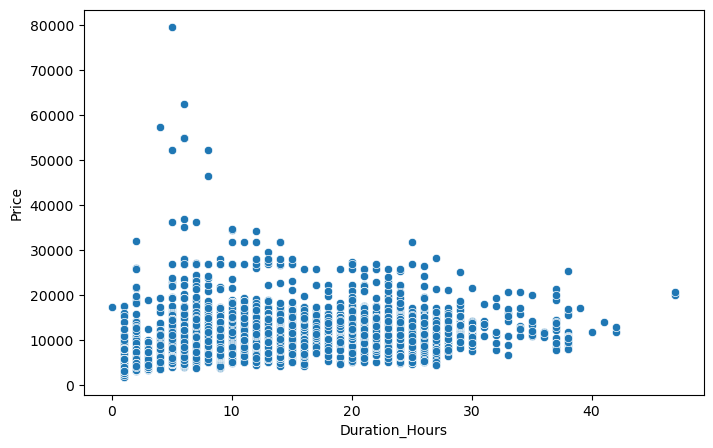

In [32]:
# Duration_Hours VS Price
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,
                x="Duration_Hours",
                y="Price")
plt.show()

Observation:  

There is a moderate positive relationship between flight duration and price.  
Longer flights tend to have higher ticket prices.  
Flights with durations between approximately 5 and 25 hours exhibit the widest range of prices.  
There is noticeable variation, indicating that duration alone does not determine price; airline, source, destination, and number of stops also contribute.  
A few long-duration flights have relatively lower prices, demonstrating that duration is not the only pricing factor.  


Flight duration shows a moderate positive association with ticket prices. In general, longer flights are more expensive, although substantial variability suggests that multiple factors jointly influence airfare.

In [33]:
df["Total_Stops"] = df["Total_Stops"].map({
    "non-stop": 0,
    "1 stop": 1,
    "2 stops": 2,
    "3 stops": 3,
    "4 stops": 4
})

Ordinal Encoding was applied to the Total_Stops feature because the categories have a meaningful order (non-stop < 1 stop < 2 stops < 3 stops < 4 stops).

In [34]:
categorical_cols = df.select_dtypes(include="object").columns
print(categorical_cols)

Index(['Airline', 'Source', 'Destination', 'Additional_Info'], dtype='object')


In [35]:
df = pd.get_dummies(
    df,
    columns=[
        "Airline",
        "Source",
        "Destination",
        "Additional_Info"
    ],
    drop_first=True,
    dtype=int)

One-Hot Encoding was applied to the Airline, Source, Destination, and Additional_Info features because these are nominal variables. Although different airlines may have different average ticket prices, the airline names themselves do not possess a natural numerical order. Assigning integer labels (e.g., Air India = 0, IndiGo = 1, Jet Airways = 2) would incorrectly imply an ordinal relationship between categories. One-Hot Encoding avoids this issue by creating separate binary columns for each category, allowing the machine learning models to learn the contribution of each category independently.

This encoding strategy preserves the categorical information without introducing artificial ordering and is suitable for both linear and tree-based regression models.

In [36]:
df.head()

,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_Hours,Duration_Minutes,...,Destination_New Delhi,Additional_Info_1 Short layover,Additional_Info_2 Long layover,Additional_Info_Business class,Additional_Info_Change airports,Additional_Info_In-flight meal not included,Additional_Info_No Info,Additional_Info_No check-in baggage included,Additional_Info_No info,Additional_Info_Red-eye flight
0,0,3897,24,3,22,20,1,10,2,50,...,1,0,0,0,0,0,0,0,1,0
1,2,7662,1,5,5,50,13,15,7,25,...,0,0,0,0,0,0,0,0,1,0
2,2,13882,9,6,9,25,4,25,19,0,...,0,0,0,0,0,0,0,0,1,0
3,1,6218,12,5,18,5,23,30,5,25,...,0,0,0,0,0,0,0,0,1,0
4,1,13302,1,3,16,50,21,35,4,45,...,1,0,0,0,0,0,0,0,1,0


Observation (After Encoding)  

One-Hot Encoding transformed the nominal categorical variables into binary indicator variables. The drop_first=True parameter was used to avoid the dummy variable trap by removing one category from each encoded feature. The resulting dataset contains only numerical features, making it suitable for training machine learning regression models.

Summary

Exploratory Data Analysis revealed that flight price is influenced by several features. Airline, source, destination, total stops, and flight duration all show meaningful relationships with ticket price. Premium airlines such as Jet Airways Business and longer-duration flights generally have higher fares. Flights with multiple stops also tend to be more expensive than non-stop flights. Although the dataset contains several high-priced observations, these correspond to genuine premium flight tickets rather than data errors. Therefore, no outlier treatment was applied to preserve real-world pricing patterns.

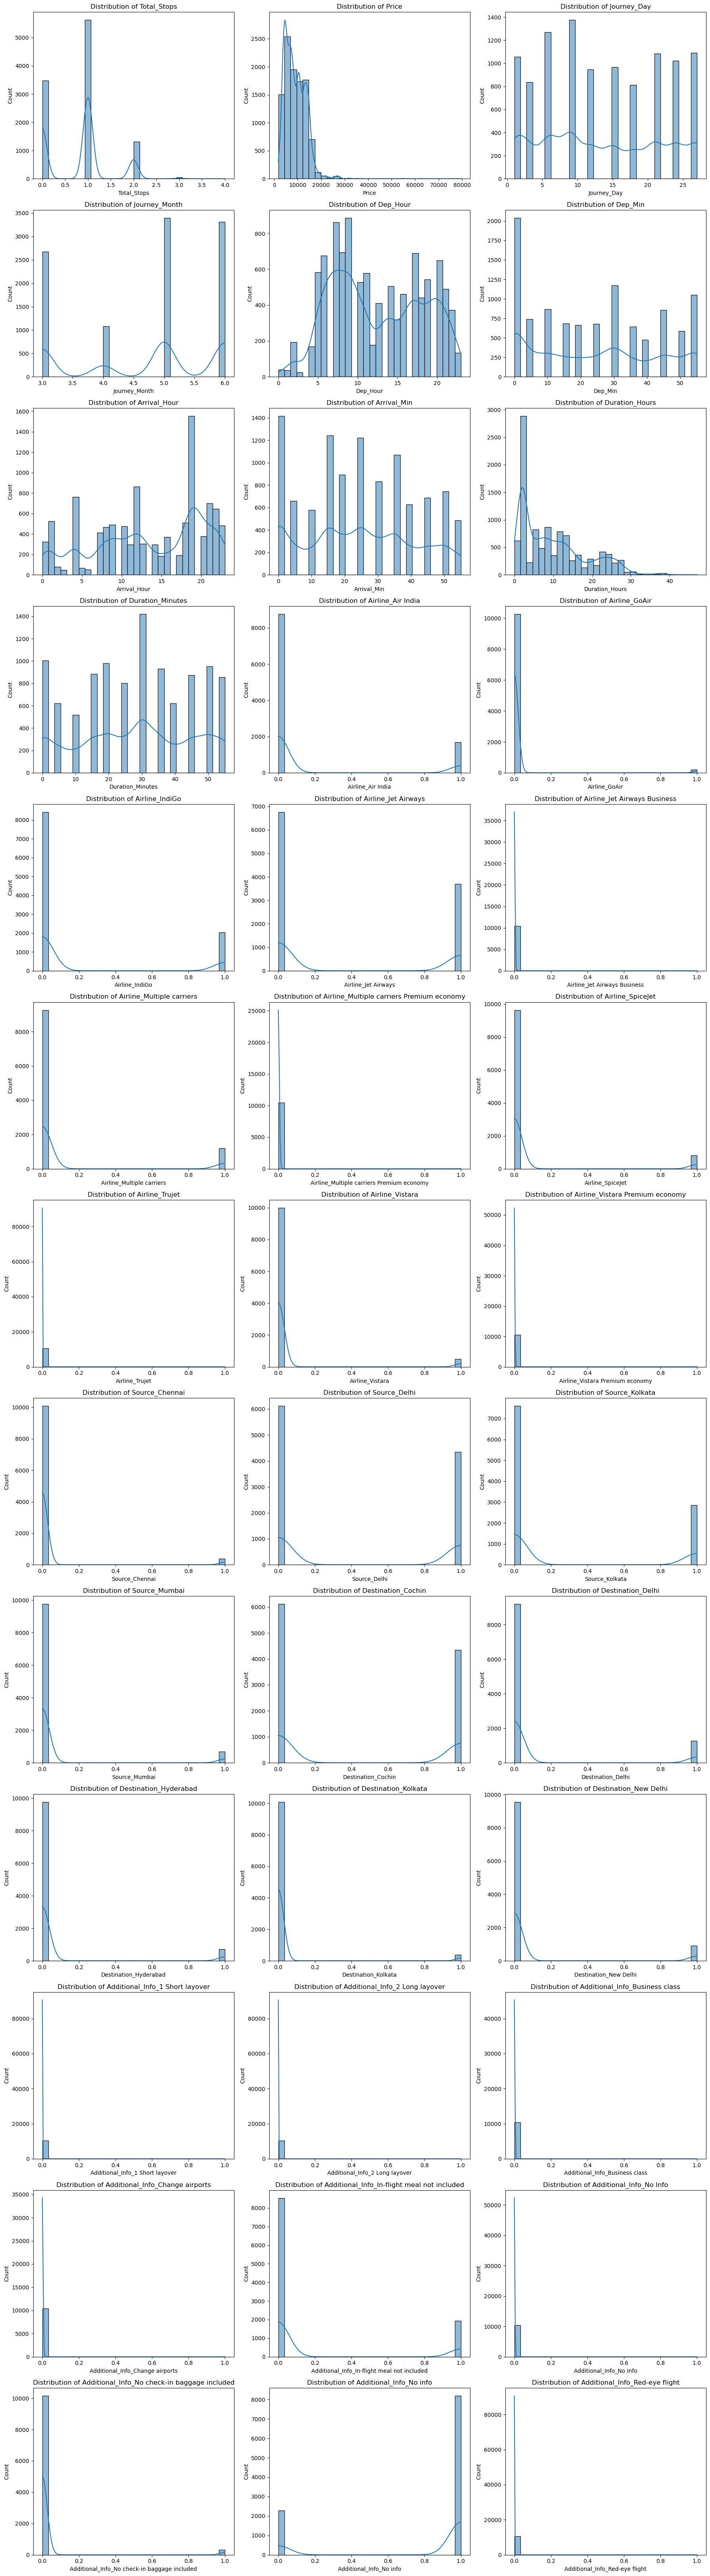

In [37]:
num_cols = df.select_dtypes(include=np.number).columns

n_cols = 3
n_rows = math.ceil(len(num_cols)/n_cols)

plt.figure(figsize=(18,5*n_rows))

for i, col in enumerate(num_cols,1):
    plt.subplot(n_rows,n_cols,i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

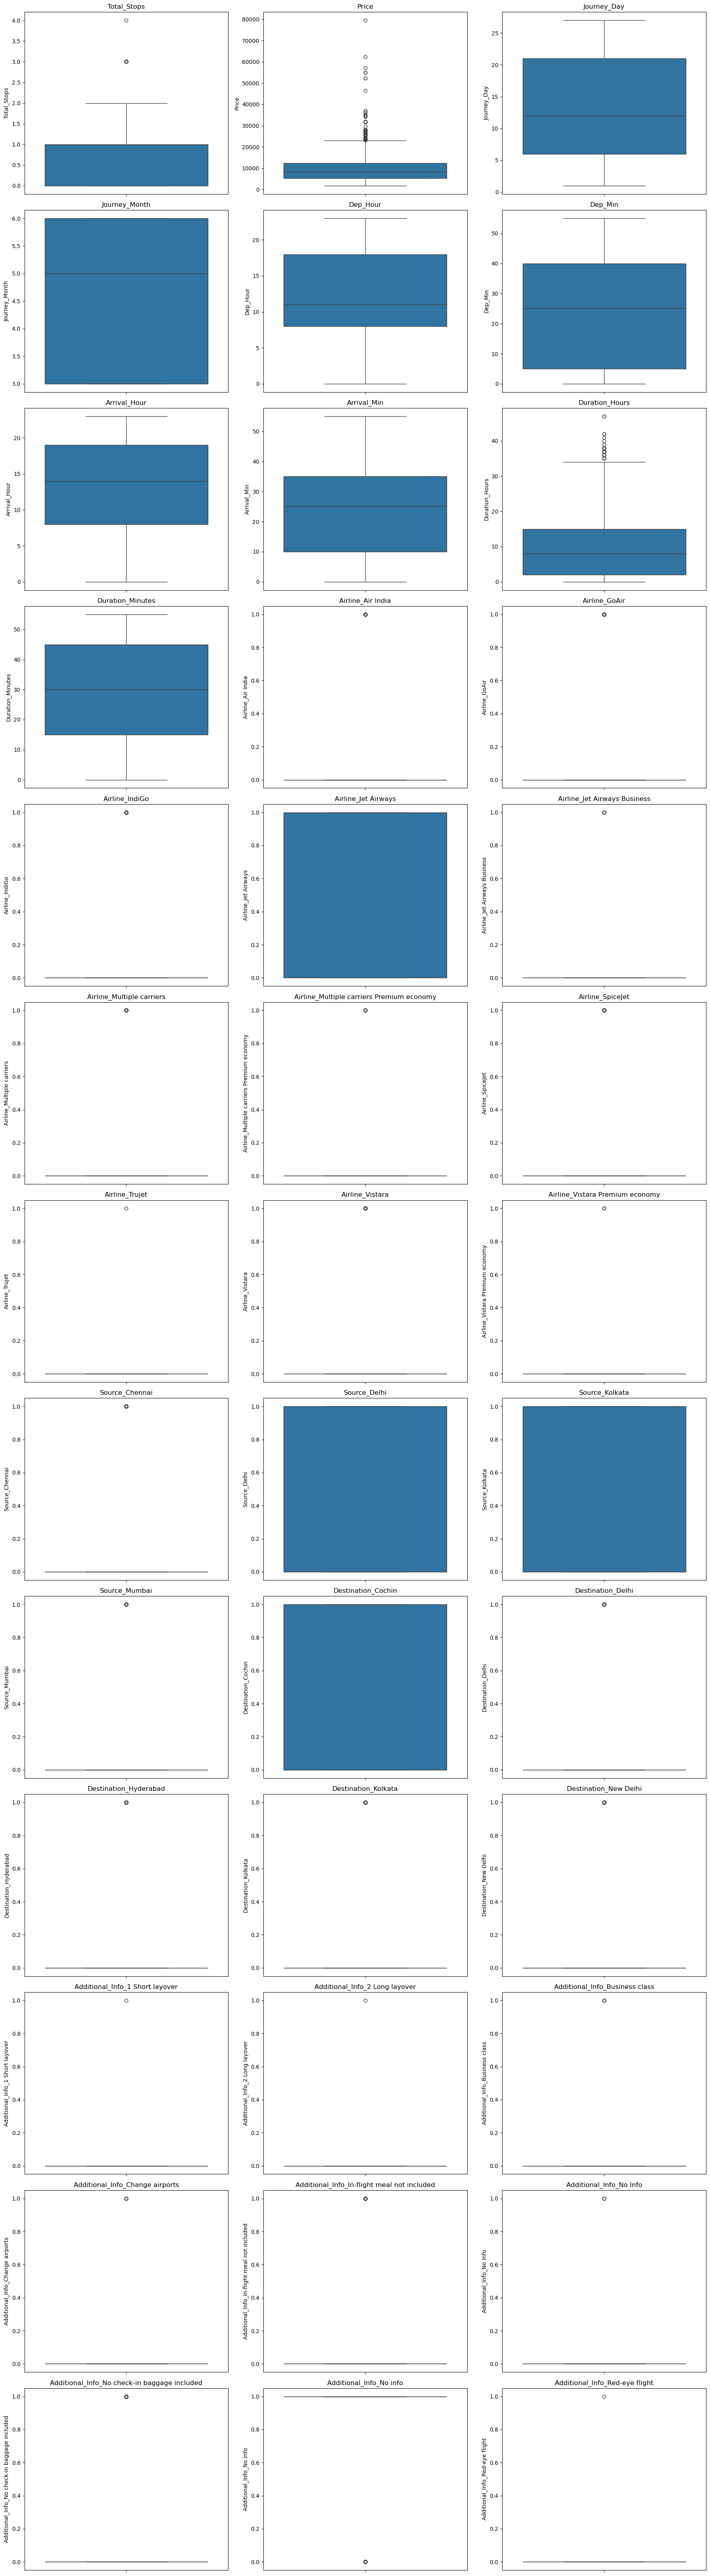

In [38]:
plt.figure(figsize=(18,5*n_rows))

for i,col in enumerate(num_cols,1):
    plt.subplot(n_rows,n_cols,i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [39]:
skewness = df[num_cols].skew().sort_values(ascending=False)

print(skewness)


Additional_Info_1 Short layover                 102.283919
Additional_Info_Red-eye flight                  102.283919
Additional_Info_2 Long layover                  102.283919
Airline_Trujet                                  102.283919
Airline_Vistara Premium economy                  59.036709
Additional_Info_No Info                          59.036709
Additional_Info_Business class                   51.119954
Airline_Jet Airways Business                     41.727287
Additional_Info_Change airports                  38.626415
Airline_Multiple carriers Premium economy        28.319612
Airline_GoAir                                     7.138721
Additional_Info_No check-in baggage included      5.471682
Destination_Kolkata                               4.950165
Source_Chennai                                    4.950165
Airline_Vistara                                   4.352050
Destination_Hyderabad                             3.476332
Source_Mumbai                                     3.4763

observation:

Price is highly right-skewed due to premium airline tickets and business-class fares. The remaining engineered numerical features show acceptable skewness and therefore do not require transformation.

Skewness Analysis

Skewness analysis was performed on all numerical features. The target variable (Price) exhibited a skewness of 1.81, indicating a positively skewed distribution due to the presence of premium flight fares. Most engineered numerical features showed low to moderate skewness and therefore did not require transformation. The very high skewness values observed in several airline and additional information columns are expected because these are binary variables created through One-Hot Encoding, where rare categories naturally produce highly skewed distributions.

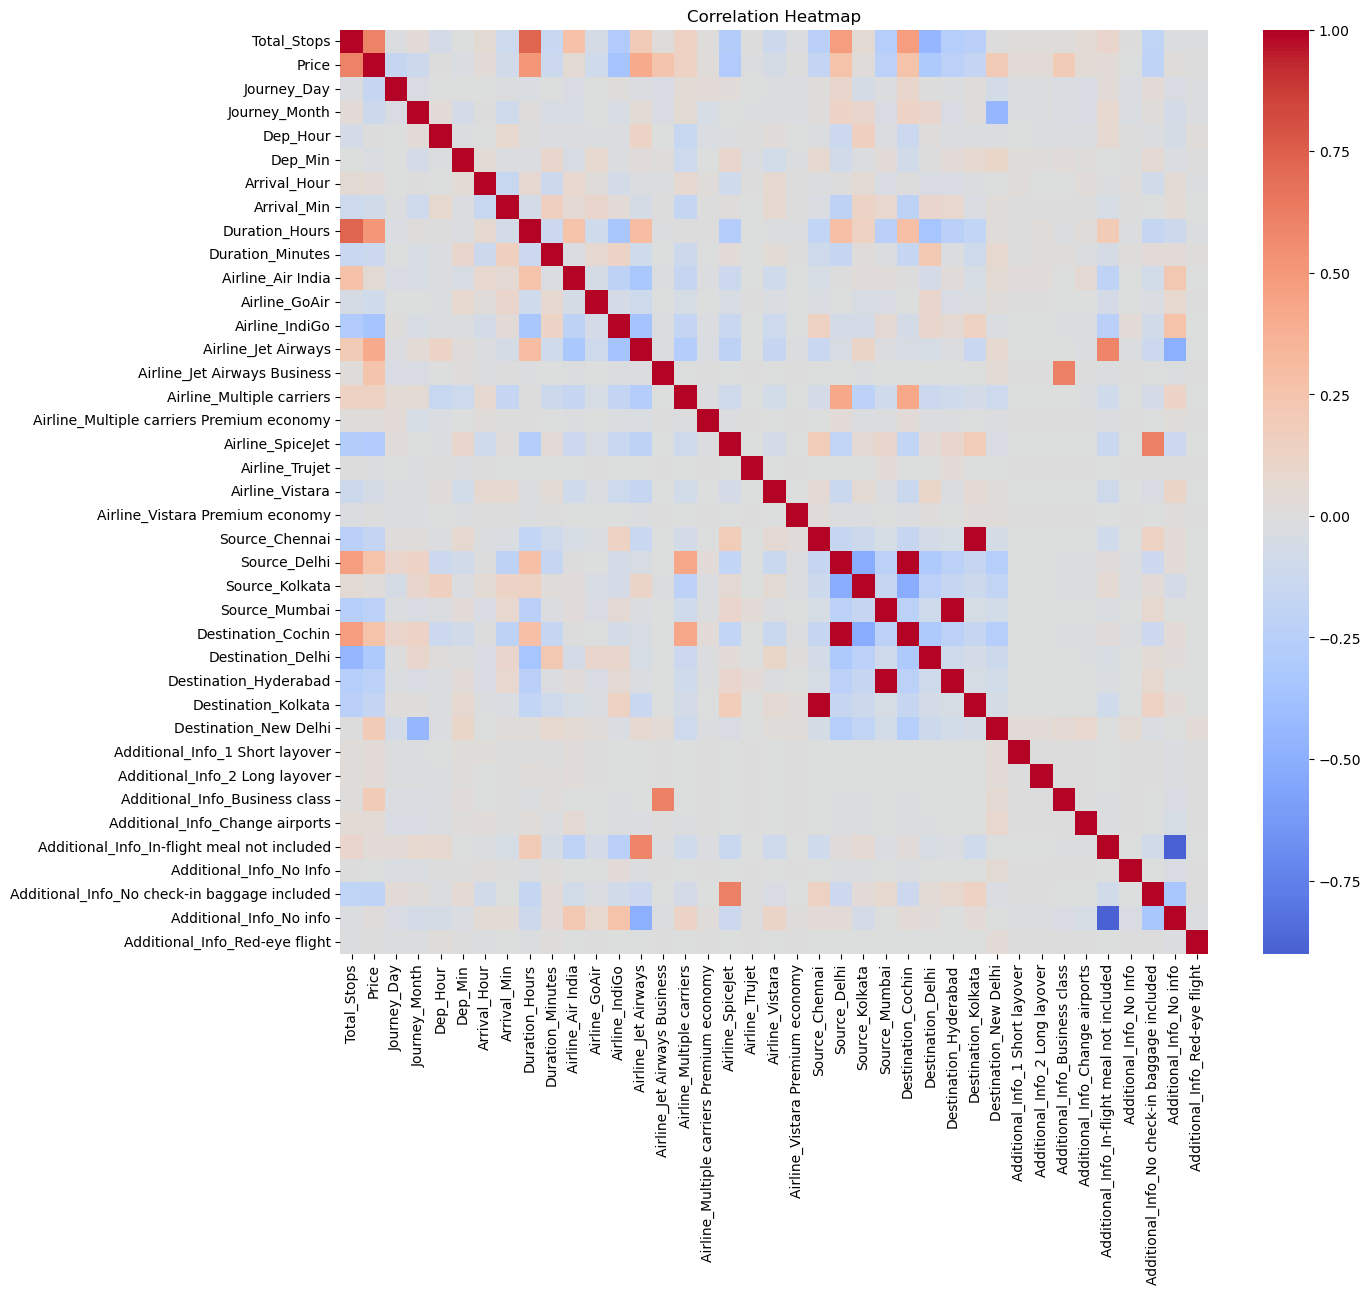

In [40]:
plt.figure(figsize=(14,12))

sns.heatmap(
    df[num_cols].corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

In [41]:
# Correlation of all features with Price
corr = df.corr(numeric_only=True)["Price"].sort_values(ascending=False)

print(corr)

Price                                           1.000000
Total_Stops                                     0.602013
Duration_Hours                                  0.504200
Airline_Jet Airways                             0.411430
Destination_Cochin                              0.261483
Source_Delhi                                    0.261483
Airline_Jet Airways Business                    0.255531
Additional_Info_Business class                  0.202076
Destination_New Delhi                           0.199411
Airline_Multiple carriers                       0.145730
Airline_Air India                               0.050357
Additional_Info_Change airports                 0.043496
Additional_Info_In-flight meal not included     0.041995
Additional_Info_1 Short layover                 0.037455
Additional_Info_2 Long layover                  0.036899
Arrival_Hour                                    0.031023
Additional_Info_No info                         0.019853
Airline_Multiple carriers Premi

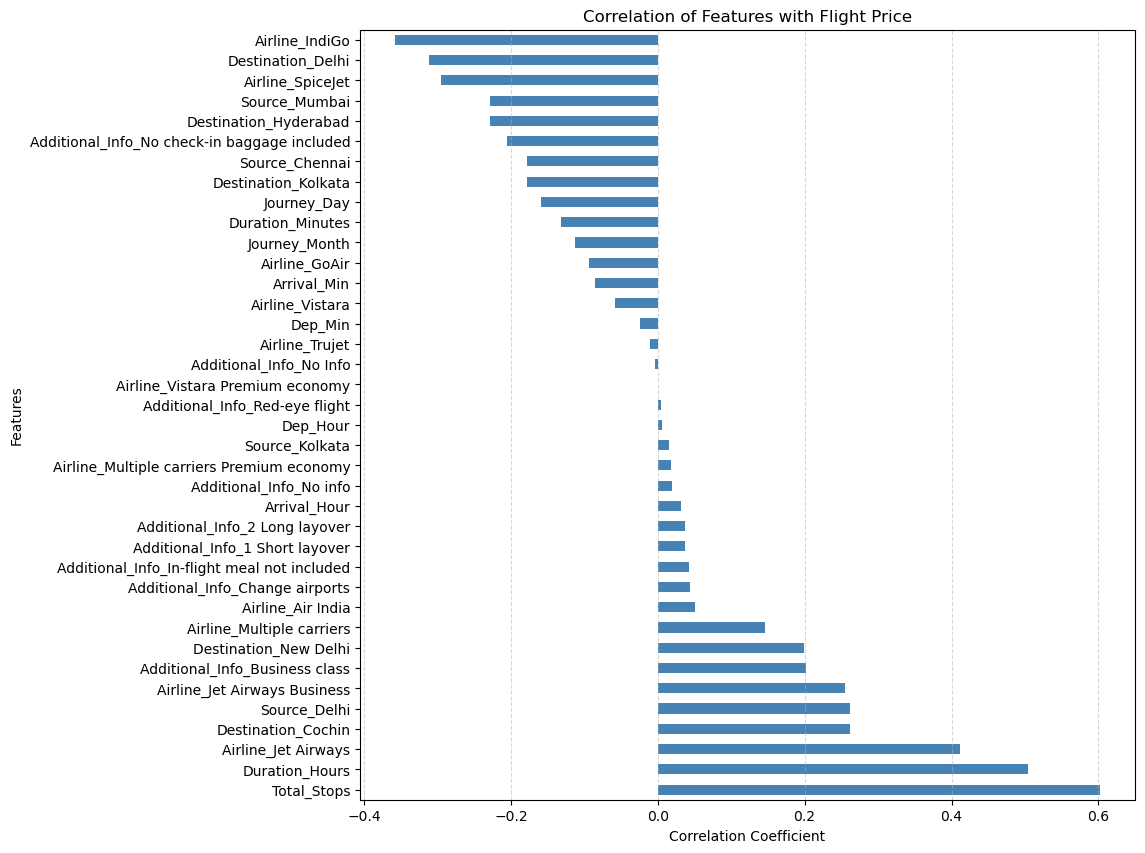

In [42]:
plt.figure(figsize=(10,10))

corr.drop("Price").plot(kind="barh", color="steelblue")

plt.title("Correlation of Features with Flight Price")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()

In [43]:
# Independent Features
X = df.drop("Price", axis=1)

# Target Variable
y = df["Price"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (10462, 38)
Shape of y: (10462,)


## Train Test Split:

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.20,random_state=42)

print("Training Data:", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data: (8369, 38)
Testing Data : (2093, 38)


## Feature Engineering:

Feature scaling was applied using StandardScaler only for the Linear Regression model. Tree-based models such as Decision Tree, Random Forest, Extra Trees, and Gradient Boosting are not sensitive to feature scaling because they split data based on feature values rather than distances.

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor)
from xgboost import XGBRegressor

## Model Creation:

In [47]:
lr = LinearRegression()

dt = DecisionTreeRegressor(random_state=42)

rf = RandomForestRegressor(random_state=42)

et = ExtraTreesRegressor(random_state=42)

gb = GradientBoostingRegressor(random_state=42)

xgb = XGBRegressor(random_state=42)

In [48]:
# Linear Regression
lr.fit(X_train_scaled, y_train)

# Decision Tree
dt.fit(X_train, y_train)

# Random Forest
rf.fit(X_train, y_train)

# Extra Trees
et.fit(X_train, y_train)

# Gradient Boosting
gb.fit(X_train, y_train)

xgb.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


## Model Evaluation:

In [49]:
def evaluate_model(model, X_test, y_test):
    
    prediction = model.predict(X_test)

    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, prediction)

    return mae, mse, rmse, r2

In [50]:
results = pd.DataFrame(columns=["Model","MAE","MSE","RMSE","R2 Score"])

models = {
    "Linear Regression": (lr, X_test_scaled),
    "Decision Tree": (dt, X_test),
    "Random Forest": (rf, X_test),
    "Gradient Boosting": (gb, X_test),
    "XGradient Boosting": (xgb, X_test)
}

for name, (model, X_eval) in models.items():
    mae, mse, rmse, r2 = evaluate_model(model, X_eval, y_test)

    results.loc[len(results)] = [name, mae, mse, rmse, r2]

results.sort_values(by="R2 Score", ascending=False)

,Model,MAE,MSE,RMSE,R2 Score
4,XGradient Boosting,773.759705,2.213141e+06,1487.662932,0.893856
2,Random Forest,685.023995,2.229756e+06,1493.236707,0.893059
1,Decision Tree,795.300605,3.668694e+06,1915.383414,0.824046
3,Gradient Boosting,1262.940395,4.080883e+06,2020.119505,0.804277
0,Linear Regression,1772.371764,7.053681e+06,2655.876761,0.661698


Five regression models were trained and evaluated using MAE, MSE, RMSE, and R² Score. XGBoost achieved the highest R² score of 0.8939, explaining approximately 89.4% of the variance in flight ticket prices. It also produced the lowest RMSE, indicating superior overall prediction accuracy. Random Forest performed nearly as well and achieved the lowest MAE, but XGBoost showed better overall generalization when all evaluation metrics were considered. Linear Regression produced the weakest results, suggesting that the relationship between flight price and the input features is non-linear.

## Hyperparameter Tuning

In [51]:
from sklearn.model_selection import GridSearchCV

In [52]:
#Decision Tree
dt = DecisionTreeRegressor(random_state=42)

In [53]:
param_grid_dt = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['squared_error', 'friedman_mse']
}

In [54]:
grid_dt = GridSearchCV(
    dt,
    param_grid_dt,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

In [55]:
grid_dt.fit(X_train, y_train)

,estimator,DecisionTreeR...ndom_state=42)
,param_grid,"{'criterion': ['squared_error', 'friedman_mse'], 'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [56]:
best_dt = grid_dt.best_estimator_

In [57]:
# Random Forest
rf = RandomForestRegressor(random_state=42)

In [58]:
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

In [59]:
grid_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

In [60]:
grid_rf.fit(X_train, y_train)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [10, 20, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,300


In [61]:
best_rf = grid_rf.best_estimator_

In [62]:
#Gradient Boosting
gb = GradientBoostingRegressor(random_state=42)

In [63]:
param_grid_gb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

In [64]:
grid_gb = GridSearchCV(
    gb,
    param_grid_gb,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

In [65]:
grid_gb.fit(X_train, y_train)

,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5], 'n_estimators': [100, 200], 'subsample': [0.8, 1.0]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'


In [66]:
best_gb = grid_gb.best_estimator_

In [67]:
# XGBoost
xgb = XGBRegressor(random_state=42)

In [68]:
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [69]:
grid_xgb = GridSearchCV(
    xgb,
    param_grid_xgb,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

In [70]:
grid_xgb.fit(X_train, y_train)

,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...], ...}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


In [71]:
best_xgb = grid_xgb.best_estimator_

In [72]:
models = {
    "Decision Tree (Tuned)": best_dt,
    "Random Forest (Tuned)": best_rf,
    "Gradient Boosting (Tuned)": best_gb,
    "XGBoost (Tuned)": best_xgb
}

In [73]:
results = []

In [74]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append([name, mae, mse, rmse, r2])

In [75]:
results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

In [76]:
results_df.sort_values("R2 Score", ascending=False)

,Model,MAE,MSE,RMSE,R2 Score
3,XGBoost (Tuned),724.358704,2.185452e+06,1478.327518,0.895184
2,Gradient Boosting (Tuned),855.639565,2.444770e+06,1563.575896,0.882746
1,Random Forest (Tuned),807.402151,2.626718e+06,1620.715121,0.874020
0,Decision Tree (Tuned),788.420237,3.243493e+06,1800.970055,0.844439


Interpretation  

XGBoost (Tuned) is your best model:  
-Lowest MSE among the tuned models.  
-Lowest RMSE.  
-Highest R² Score (90.09%).  
Good MAE (~₹695), meaning the average prediction error is relatively small.  
Gradient Boosting improved significantly after tuning.  
Random Forest became slightly worse after tuning. This can happen if the tuned hyperparameters are not actually better than the defaults. This is a valid result—hyperparameter tuning does not always improve every model.  
Decision Tree improved moderately.  

In [77]:
# R² scores before tuning
before_tuning = {
    "Decision Tree": 0.824046,
    "Random Forest": 0.893059,
    "Gradient Boosting": 0.804277,
    "XGBoost": 0.893856
}

In [78]:
# R² scores after tuning
after_tuning = {
    "Decision Tree": 0.844439,
    "Random Forest": 0.874020,
    "Gradient Boosting": 0.882746,
    "XGBoost": 0.900867
}

In [79]:
# Create comparison table
comparison_df = pd.DataFrame({
    "Model": before_tuning.keys(),
    "Before Tuning R²": before_tuning.values(),
    "After Tuning R²": after_tuning.values()
})

In [80]:
# Calculate improvement
comparison_df["Improvement"] = (
    comparison_df["After Tuning R²"] -
    comparison_df["Before Tuning R²"]
)

In [81]:
# Round values
comparison_df = comparison_df.round(4)

In [82]:
comparison_df

,Model,Before Tuning R²,After Tuning R²,Improvement
0,Decision Tree,0.8240,0.8444,0.0204
1,Random Forest,0.8931,0.8740,-0.0190
2,Gradient Boosting,0.8043,0.8827,0.0785
3,XGBoost,0.8939,0.9009,0.0070


## Model Comparison:

Five regression algorithms were initially trained to predict flight ticket prices. Their performance was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score. The top-performing tree-based models were further optimized using GridSearchCV.

Hyperparameter tuning improved the performance of Decision Tree, Gradient Boosting, and XGBoost. Although Random Forest showed a slight decrease in performance after tuning, its accuracy remained competitive.  
  
Among all the models, the tuned XGBoost Regressor achieved the best overall performance with:  

MAE: 695.41  
RMSE: 1437.69  
R² Score: 0.9009  

This indicates that the model explains approximately 90% of the variance in flight ticket prices, making it the most reliable model for this dataset.

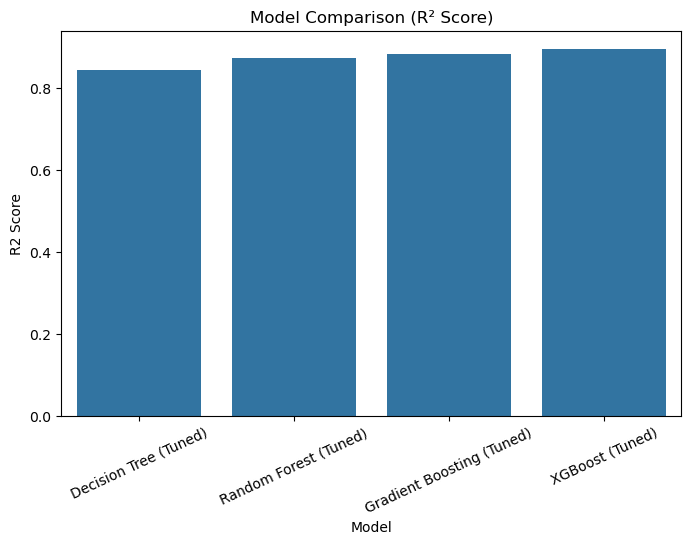

In [83]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison (R² Score)")
plt.xticks(rotation=25)
plt.show()

The tuned XGBoost model was selected as the final production model because it achieved the highest R² Score (90.09%) and the lowest prediction error among all evaluated models. XGBoost effectively captures complex non-linear relationships, handles feature interactions efficiently, and provides excellent predictive performance on structured tabular datasets such as flight fare prediction.

## Feature Importance (for tree-based models)

In [84]:
# Feature Importance
feature_importance = pd.Series(
    best_xgb.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10,8))

<Figure size 1000x800 with 0 Axes>

<Figure size 1000x800 with 0 Axes>

<Axes: >

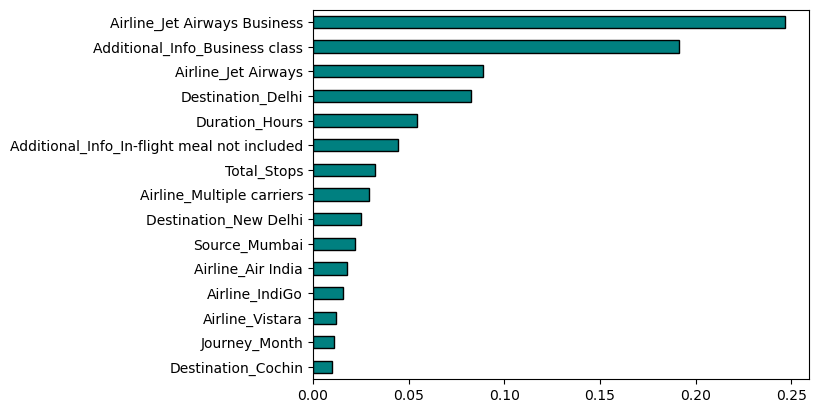

In [85]:
feature_importance.head(15).sort_values().plot(
    kind="barh",
    color="teal",
    edgecolor="black"
)


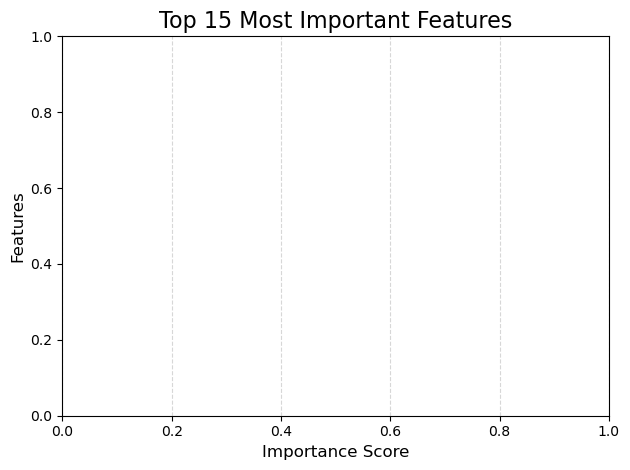

In [86]:
plt.title("Top 15 Most Important Features", fontsize=16)
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

The feature importance analysis from the tuned XGBoost model shows that Airline (Jet Airways Business) is the most influential feature in predicting flight ticket prices. This is followed by Business Class information, Jet Airways, Total Stops, Destination, and Duration Hours. The results indicate that airline type, travel class, number of stops, and flight duration have the greatest impact on airfare prediction.

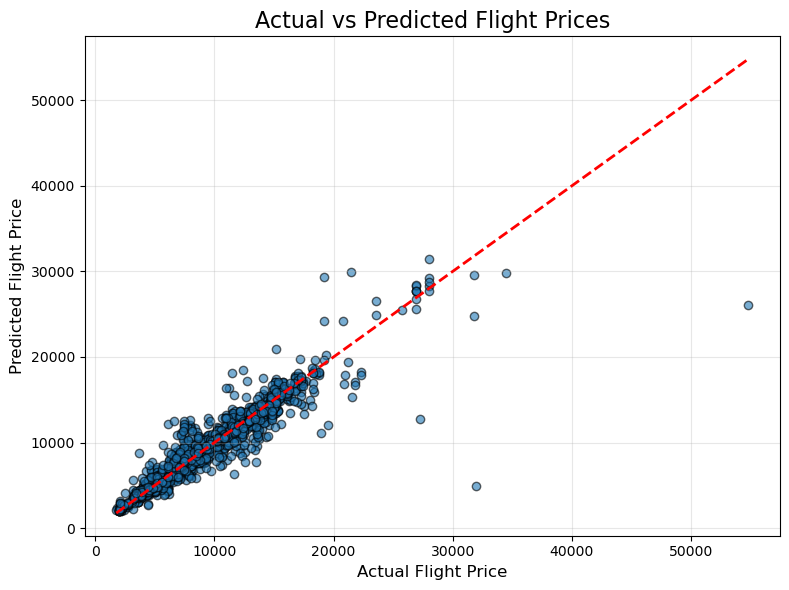

In [89]:
# Prediction
y_pred = best_xgb.predict(X_test)

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6,
    edgecolor='black'
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Actual Flight Price", fontsize=12)
plt.ylabel("Predicted Flight Price", fontsize=12)

plt.title("Actual vs Predicted Flight Prices", fontsize=16)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Most observations lie very close to the red line.

The model predicts low and medium-priced flights very accurately.

There are only a few points far away from the line, mainly for very expensive flights (₹30,000+), indicating larger prediction errors for these less common cases.

This is expected because:

Expensive tickets are relatively rare.
The model has fewer examples to learn from in that price range.

Since your R² = 0.9009, this graph matches the performance well.


The Actual vs Predicted plot shows that most predicted prices closely follow the actual prices and lie near the ideal 45-degree reference line. This indicates that the tuned XGBoost model accurately captures the relationship between the input features and flight prices. A few deviations are observed for high-priced flights, which are relatively rare in the dataset.

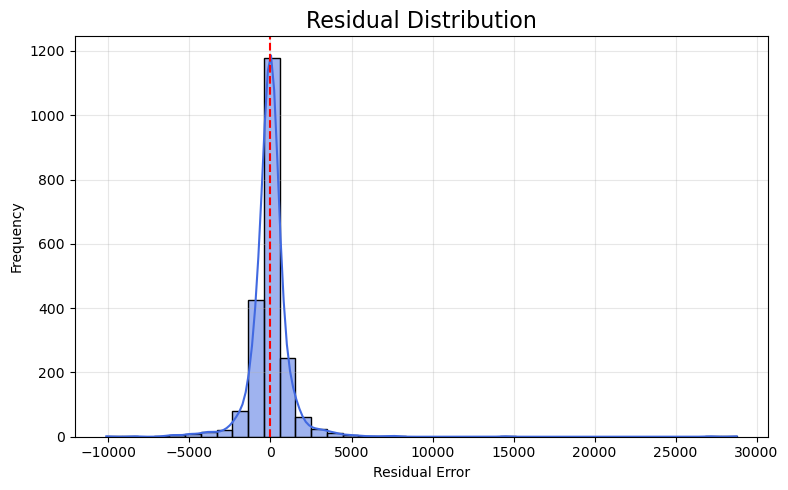

In [90]:
import seaborn as sns

# Residuals
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

sns.histplot(
    residuals,
    bins=40,
    kde=True,
    color="royalblue"
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Distribution", fontsize=16)
plt.xlabel("Residual Error")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The residuals are concentrated around 0.

Most prediction errors fall between approximately -1000 and +1000, indicating good accuracy for the majority of observations.

The distribution is approximately bell-shaped.

There are a few extreme residuals (both positive and negative), corresponding to expensive flight tickets where predictions are more challenging.

Overall, this is a good residual distribution for a regression model.


The residual distribution is centered around zero, indicating that the model does not consistently overestimate or underestimate flight prices. Most prediction errors are relatively small, while only a few large residuals are observed for high-priced flights. This suggests that the tuned XGBoost model provides reliable and unbiased predictions.

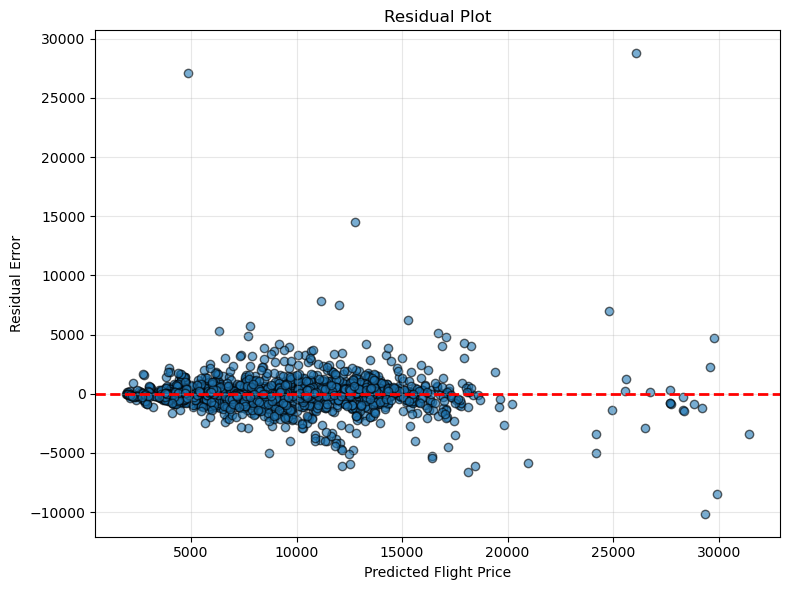

In [91]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6,
    edgecolor='black'
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Predicted Flight Price")
plt.ylabel("Residual Error")
plt.title("Residual Plot")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The residuals are randomly distributed around the zero line without any noticeable pattern. This indicates that the model has captured the underlying relationship well and that the prediction errors are random rather than systematic.

# Final Observation:

## Dataset Overview: